# Mixed-mode delamination of IM7/8552: DCB and MMB tests of Raimondo et al.

A. Raimondo, I. Urcelay Oca and C. Bisagni, *Influence of interface ply orientation on delamination growth in composite laminates*, J. Compos. Mater. 2021; 55(27):3955-3972, https://doi.org/10.1177/00219983211031636.

Unidirectional IM7/8552 specimens, $[0_{12}//0_{12}]$, tested in the double cantilever beam (DCB) and mixed-mode bending (MMB) configurations at $G_{II}/G$ = 20 and 50%, three specimens per test. Raimondo et al. analyse the tests with shell elements and the virtual crack closure technique (VCCT) in ABAQUS, with and without an R-curve; the analyses without R-curve use the same toughness as the cohesive law here.

`panels` models the three tests with the coupons of `panels.multidomain.delamination.create_coupon`, two plate arms joined by the mixed-mode bilinear cohesive law (theory: [mixed-mode cohesive zone](../cohesive_zone_mixed_mode.rst)), with CLPT and with FSDT arms. Linear elastic fracture mechanics (LEFM), the corrected beam theory of ASTM D6671/D6671M-22, is computed here as a further reference.

Two inputs are not published and are **identified** here: the crack length of the pre-cracked DCB specimens, from the analytical DCB curve of Raimondo et al.; and, since `panels` does not apply the weight of the MMB lever, the shift of the computed MMB curves to the frame of the tests is computed with LEFM.

In [1]:
%matplotlib inline
import math
import os
import sys

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

sys.path.insert(0, os.path.abspath('.'))
import mmb_utils as mu
from panels.multidomain.connections.czm import BilinearLaw

# True runs panels and saves the results in RESULTS, False loads them
RERUN = bool(int(os.environ.get('MMB_RERUN', '0')))
RESULTS = 'results'
REFERENCE = os.path.join('reference_data', 'case4c_raimondo2021')
# comma-separated keys, e.g. MMB50_clpt, runs only these (used to run in parallel)
ONLY = os.environ.get('MMB_TESTS')
ONLY = ONLY.split(',') if ONLY else None

## Specimen and material data

- Ply properties, Raimondo et al. (2021), Table 1, p. 4: $E_{11}$ = 146 GPa, $E_{22}$ = 8.22 GPa, $G_{12}$ = 4.5 GPa, $\nu_{12}$ = 0.34. Not published, taken from another source: $G_{13}$ = 5.2 GPa and $G_{23}$ = 3.9 GPa of IM7/8552 in R. Krueger, *Development and application of benchmark examples for mixed-mode I/II quasi-static delamination propagation predictions*, NASA/CR-2012-217562, 2012, Table I (whose $E_{11}$, $E_{22}$ and $G_{12}$ differ from those of Raimondo et al.). Only the FSDT arms use them; in the study, the transversely isotropic set built from Table 1 ($G_{13}$ = 4.5 GPa, $G_{23}$ = 2.83 GPa) changed the FSDT peaks by less than 0.6%.
- Specimen, Raimondo et al. (2021), p. 4 and Fig. 3: width 25 mm, thickness 3 mm (arm $h$ = 1.5 mm; the ply thickness 0.125 mm = 3/24 is inferred), 147 mm long, insert 25 mm from the load line; MMB half-span $L$ = 50.4 mm, lever lengths $c$ = 96.24 and 41.76 mm (p. 5). The MMB specimens were not pre-cracked (p. 8): $a_0$ = 25 mm.
- **DCB crack length, identified: $a_0$ = 29.8 mm.** The DCB specimens were pre-cracked by "a few millimetres" (p. 8); the crack length after pre-cracking is not reported. It is identified from the analytical DCB curve of Raimondo et al. (Fig. 28, p. 16, modified beam theory), not from the tests: with $G_{Ic}$ = 0.230 N/mm, its peak load and its compliance at the peak both give $a_0 + \chi h$ = 32.7-32.8 mm with the corrected beam theory of ASTM D6671-22, i.e. $a_0$ = 29.8 mm (code below). With the nominal 25 mm the DCB model was 79% stiffer than the tests in the study.
- Interface: one bilinear law with the toughness of the Benzeggagh-Kenane fit of the onset values, Table 5, p. 13: $G_{Ic}$ = 0.230 N/mm, $G_{IIc}$ = 0.739 N/mm (from the literature; no ENF test), $\eta$ = 2.50, the toughness of the VCCT analyses without R-curve. The rise from onset to plateau in Table 4, p. 13 (+6% DCB, +26% MMB 20%, 0% MMB 50%) does not follow the pattern of a mode I bridging law, and the paper reports no fibre bridging, so no bridging law is added. Strengths, **chosen** (not published for this VCCT study): $\tau_I$ = 60 MPa, within the values used for IM7/8552 (50 MPa, J. Xie, A. M. Waas and M. Rassaian, Int. J. Solids Struct. 2016; 88-89:379-400, https://doi.org/10.1016/j.ijsolstr.2015.12.025, Table 1; 62.3 MPa, R. Butler, C. Fallon, T. Maierhofer and D. Kennedy, Compos. Struct. 2026; 379:119957, https://doi.org/10.1016/j.compstruct.2025.119957, Table 1, p. 4), and $\tau_{II} = \tau_I\sqrt{G_{IIc}/G_{Ic}}$ = 107.5 MPa; in the study, $\tau_I$ = 30 and 50 MPa changed the peaks by at most 3.2%. Penalty stiffness $K_I = 10^5$ N/mm$^3$, the production value of the study, and the consistent shear stiffness.
- **MMB lever weight**: 17.6 N (lever and apparatus, 1.793 kg) at $c_g$ = 60 mm (20%) and 43.5 mm (50%), Raimondo et al. (2021), p. 8; the test load excludes it (Eq. 18, p. 8). `create_coupon` does not model the lever weight. The MMB curves of `panels` are mapped to the frame of the tests, $P_{test} = P - \Delta P$ and $\delta_{test} = \delta - \Delta P/K_0$, with $K_0$ the initial stiffness of the run and $\Delta P$ the difference between the LEFM curves without and with the weight (ASTM D6671-22 Eqs. 17-18), which is constant along the curves within 0.05 N. The static equivalent of the weight is a load at the lever load point plus a small force at the saddle; the remaining error is about 0.5% on the load.

In [2]:
laminaprop = (146000., 8220., 0.34, 4500., 5200., 3900.)    # E11, E22, nu12, G12, G13, G23
E11, E22, _, _, G13, _ = laminaprop
plyt, stack = 0.125, [0]*12                                # arm: 12 plies, h = 1.5 mm
h = plyt*len(stack)
b, L, x_end = 25., 50.4, 147.
GIc, GIIc, eta, tauI, KI = 0.230, 0.739, 2.50, 60., 1e5
tauII = 107.5                                              # tauI*sqrt(GIIc/GIc), rounded
law = BilinearLaw(GIc, GIIc, tauI, tauII, KI, eta)
print(law)
P_g = 17.6                                                 # lever weight (N)

# B = G_II/G (nominal), c_g: lever length of the centre of gravity of the lever
tests = {
    'DCB':   dict(kind='DCB', B=0.0, a0=29.8, L_coh=70., delta_max=7.),
    'MMB20': dict(kind='MMB', B=0.2, a0=25., c=96.24, c_g=60., L_coh=75.8, delta_max=8.5),
    'MMB50': dict(kind='MMB', B=0.5, a0=25., c=41.76, c_g=43.5, L_coh=75.8, delta_max=6.),
}

BilinearLaw(GIc=0.23, GIIc=0.739, tauI=60.0, tauII=107.5, KI=100000.0, eta=2.5, KII=99907.4387310179)


### Identification of the DCB crack length

From the peak $P_c$ of the analytical curve, $G_{Ic} = 12 P_c^2 (a + \chi h)^2/(b^2 h^3 E_{11})$, and from the compliance at the peak, $\delta_c/P_c = 8(a + \chi h)^3/(b h^3 E_{11})$ (ASTM D6671-22, mode I parts of Eqs. 10 and 12, with $\chi$ of Sec. 3.3).

In [3]:
analytical_dcb = mu.read_curve(os.path.join(REFERENCE, 'Raimondo2021_Fig28_DCB_analytical.csv'))
d, P = analytical_dcb
i = int(np.nanargmax(P))
Pc, dc = P[i], d[i]
x = mu.chi(E11, E22, G13)
aeq_peak = math.sqrt(GIc*b**2*h**3*E11/12.)/Pc
aeq_slope = (dc/Pc*b*h**3*E11/8.)**(1./3.)
print('analytical curve, Fig. 28: peak {0:.1f} N at {1:.3f} mm; chi h = {2:.3f} mm'.format(Pc, dc, x*h))
print('a + chi h from the peak: {0:.2f} mm, from the compliance: {1:.2f} mm'.format(aeq_peak, aeq_slope))
print('a0 = {0:.2f} / {1:.2f} mm; used: {2} mm'.format(aeq_peak - x*h, aeq_slope - x*h, tests['DCB']['a0']))

analytical curve, Fig. 28: peak 74.3 N at 1.704 mm; chi h = 2.862 mm
a + chi h from the peak: 32.69 mm, from the compliance: 32.80 mm
a0 = 29.82 / 29.94 mm; used: 29.8 mm


## Reference data

Raimondo et al. (2021) give no table of peak loads; the curves are digitised from the raster figures (reading error about $\pm$1.5 pixel, 0.01-0.03 mm and 0.3-1.1 N; where curves overlap only the top one is visible, so the records have gaps):

- tests: DCB Fig. 9(a), p. 9; MMB 20% Fig. 14(a), p. 11; MMB 50% Fig. 18(a), p. 12; three specimens each. In the MMB at 50% the load rises again after about 3.5 mm, when the crack passes the saddle;
- VCCT analyses without R-curve: Figs. 28, 30 and 32, pp. 16-17 (the MMB analyses include the lever weight as an equivalent force and moment, p. 15); and the analytical DCB curve of Fig. 28, used above.

The peak loads are the first maxima, $\delta$ < 5 mm; the reference is the mean of the three tests.

In [4]:
fig_of = {'DCB': ('Fig9a_DCB', 'Fig28_DCB', 'DCB'), 'MMB20': ('Fig14a_MMB20', 'Fig30_MMB20', 'MMB20'),
          'MMB50': ('Fig18a_MMB50', 'Fig32_MMB50', 'MMB50')}
curves, fe_curves = {}, {}
for key, (ft, ff, s) in fig_of.items():
    curves[key] = [mu.read_curve(os.path.join(REFERENCE, 'Raimondo2021_{0}_{1}-{2}.csv'.format(ft, s, n)))
                   for n in ('I', 'II', 'III')]
    fe_curves[key] = mu.read_curve(os.path.join(REFERENCE, 'Raimondo2021_{0}_FEM_noRcurve.csv'.format(ff)))


def first_peak(d, P, dmax=5.):
    d, P = np.asarray(d), np.asarray(P)
    return float(np.nanmax(np.where(d < dmax, P, np.nan)))


ref_peaks = {}
for key in tests:
    p = [first_peak(*c) for c in curves[key]]
    ref_peaks[key] = [('Test {0}'.format(n), pi) for n, pi in zip(('I', 'II', 'III'), p)] + [
        ('Tests, mean', np.mean(p)), ('VCCT, Raimondo 2021', first_peak(*fe_curves[key]))]

## Linear elastic fracture mechanics

Corrected beam theory of ASTM D6671/D6671M-22 (`mmb_utils.lefm_curve`): the compliance of Eq. 10 and the energy release rates of Eqs. 12-13 with the crack length corrections $\chi h$ (mode I) and $0.42\chi h$ (mode II); the DCB is the mode I part. Self-similar growth at $G_c = G_{Ic} + (G_{IIc} - G_{Ic}) B^\eta$ at the nominal mode ratio, up to $a = L$. The MMB curves are computed with the lever weight (Eqs. 17-18, in the frame of the tests) and without it; their difference is the shift $\Delta P$ applied to `panels`.

In [5]:
print('chi = {0:.3f}, chi h = {1:.3f} mm'.format(x, x*h))
lefm, dP = {}, {}
for key, t in tests.items():
    Gc = mu.bk(GIc, GIIc, eta, t['B'])
    if t['kind'] == 'DCB':
        lefm[key] = mu.lefm_curve('DCB', E11, E22, G13, b, h, t['a0'], Gc)
        dP[key] = 0.
        continue
    no = mu.lefm_curve('MMB', E11, E22, G13, b, h, t['a0'], Gc, L=L, c=t['c'])
    lefm[key] = mu.lefm_curve('MMB', E11, E22, G13, b, h, t['a0'], Gc, L=L, c=t['c'], P_g=P_g, c_g=t['c_g'])
    diff = no[1][1:] - lefm[key][1][1:]
    dP[key] = float(np.mean(diff))
    print('{0}: lever length of D6671 Eq. 5 for B = {1}: {2:.2f} mm (used: {3} mm); '
          'dP = {4:.2f} N ({5:.2f}-{6:.2f})'.format(key, t['B'], mu.lever_length(t['B'], t['a0'], h, x, L),
                                                    t['c'], dP[key], diff.min(), diff.max()))

chi = 1.908, chi h = 2.862 mm
MMB20: lever length of D6671 Eq. 5 for B = 0.2: 96.63 mm (used: 96.24 mm); dP = 10.36 N (10.33-10.38)
MMB50: lever length of D6671 Eq. 5 for B = 0.5: 41.84 mm (used: 41.76 mm); dP = 18.37 N (18.37-18.38)


## panels model

Coupons of `create_coupon` (see its docstring for the supports, the lever and the load): each arm is a cracked domain, seven cohesive domains over 70 mm (DCB) or 75.8 mm (MMB, up to the far support) from the crack tip and, where the bonded length is longer, a far domain with the same law; contact over the pre-crack; domains joined with the null-space method. The lever constraint of the MMB acts on the mean deflections across the width. The DCB model ends at the end of the specimen, 147 mm from the load line, where the slope of the upper arm is zero.

Discretisation, as in the study of the mixed-mode model (rules in `mmb_utils.discretisation`): $m = \min(25, \lceil 1.25\,r L_{dom}\rceil)$ terms along $x$ in each cohesive domain (24-25), with $r$ the largest decay rate of the opening and the sliding of the arms (for FSDT arms also the fast decay of Timoshenko arms); 25 Gauss points per mm along $x$, about 12 per cohesive zone length $l_{cz} = 0.88 E_{22} G_{Ic}/\tau_I^2$ = 0.46 mm; 6 across the width; $n = 4$ terms across the width; 10 terms along $x$ in the cracked and far domains.

Solver (`solve_coupon`): Newton-Raphson, displacement increments of 0.1 mm (the largest; cut automatically down to $10^{-5}$ mm), relative tolerance $10^{-9}$, control of the load-point displacement; for the MMB at 50% with CLPT arms, control of the separation at the load line (`control='load-line'`), which follows the snap-back after the peak, up to a crack length of 52 mm.

**Stored results.** The results files were converted (`mmb_utils.convert_study_run`) from the runs of the study of the mixed-mode model listed in `STUDY_RUNS`, which were made with the same inputs and settings and with `panels` commit ec104c0, whose library code is that of this version; the conversion checks the laws, the specimen, the coupon arguments, the solver settings and the size of the model built here. The runs shared a laptop with other runs of the study, so their times are only indicative.

In [6]:
STUDY_RUNS = {
    'DCB_clpt': 'DCB_a29.8_clpt_case4c_20261123_091558',
    'DCB_fsdt': 'DCB_a29.8_fsdt_case4c_20261123_100041',
    'MMB20_clpt': 'MMB20_a25_clpt_case4c_20261123_073215',
    'MMB20_fsdt': 'MMB20_a25_fsdt_case4c_20261123_074203',
    'MMB50_clpt': 'MMB50_a25_clpt_case4c_loadline_20261123_081811',
    'MMB50_fsdt': 'MMB50_a25_fsdt_case4c_20261123_075538',
}
nd, gauss_per_mm = 7, 25.


def inputs_of(key, model):
    t = tests[key]
    disc = mu.discretisation(laminaprop, h, [law], t['L_coh'], nd, model=model)
    inp = dict(kind=t['kind'], laminaprop=laminaprop, plyt=plyt, stack=stack, b=b, a0=t['a0'],
               laws=[mu.law_dict(law)], model=model, nd=nd, L_coh=t['L_coh'],
               m_crack=10, m_coh=disc['m_coh'], m_far=10, n=4,
               nr_x_gauss=int(math.ceil(gauss_per_mm*disc['L_dom'])), nr_y_gauss=6)
    if t['kind'] == 'DCB':
        inp['x_end'] = x_end
    else:
        inp.update(L=L, c=t['c'])
    return inp


def solver_of(key, model):
    s = dict(delta_max=tests[key]['delta_max'], inc=0.1, min_inc=1e-5, relTOL=1e-9)
    if key == 'MMB50' and model == 'clpt':
        s.update(control='load-line', a_stop=52.)
    return s


runs = {}
for key in tests:
    for model in ('fsdt', 'clpt'):
        name = '{0}_{1}'.format(key, model)
        if ONLY is not None and name not in ONLY:
            continue
        path = os.path.join(RESULTS, '{0}_{1}.npz'.format('mmb_raimondo2021_im78552', name))
        runs[name] = mu.run_or_load(inputs_of(key, model), solver_of(key, model), path, rerun=RERUN)

## Results

The MMB curves of `panels` are shifted to the frame of the tests (lever weight, see above); the DCB needs no shift.

In [7]:
def test_frame(res, dP):
    d, P = np.r_[0., res['delta']], np.r_[0., res['P']]
    if dP == 0.:
        return d, P
    K0 = mu.initial_stiffness(d, P)
    ds, Ps = d - dP/K0, P - dP
    keep = Ps >= 0.
    return np.r_[0., ds[keep]], np.r_[0., Ps[keep]]


shifted = {name: test_frame(res, dP[name.split('_')[0]]) for name, res in runs.items()}
for name, res in runs.items():
    print('{0}: peak {1:.1f} N without the shift, {2:.1f} N in the frame of the tests'.format(
          name, first_peak(np.r_[0., res['delta']], np.r_[0., res['P']]), first_peak(*shifted[name])))

DCB_fsdt: peak 73.4 N without the shift, 73.4 N in the frame of the tests
DCB_clpt: peak 76.3 N without the shift, 76.3 N in the frame of the tests
MMB20_fsdt: peak 67.3 N without the shift, 56.9 N in the frame of the tests
MMB20_clpt: peak 69.1 N without the shift, 58.7 N in the frame of the tests
MMB50_fsdt: peak 192.0 N without the shift, 173.7 N in the frame of the tests
MMB50_clpt: peak 198.8 N without the shift, 180.5 N in the frame of the tests


Peak loads (first maximum, $\delta$ < 5 mm): tests, the VCCT analyses of Raimondo et al. (2021), LEFM and `panels`, in the frame of the tests; the differences are to the mean of the tests.

In [8]:
rows = []
for key in tests:
    for s, p in ref_peaks[key]:
        rows.append((key, s, p))
    rows.append((key, 'LEFM (ASTM D6671)', first_peak(*lefm[key][:2])))
    for model in ('fsdt', 'clpt'):
        name = '{0}_{1}'.format(key, model)
        if name in shifted:
            rows.append((key, 'panels ' + model.upper(), first_peak(*shifted[name])))
display(Markdown(mu.peaks_table(rows, ref='Tests, mean')))

| test | source | $P_{max}$ (N) | vs Tests, mean |
|---|---|---|---|
| DCB | Test I | 75.2 | -3.5% |
| DCB | Test II | 73.9 | -5.2% |
| DCB | Test III | 84.7 | +8.7% |
| DCB | Tests, mean | 77.9 | - |
| DCB | VCCT, Raimondo 2021 | 72.5 | -7.0% |
| DCB | LEFM (ASTM D6671) | 74.4 | -4.5% |
| DCB | panels FSDT | 73.4 | -5.8% |
| DCB | panels CLPT | 76.3 | -2.1% |
| MMB20 | Test I | 64.1 | +0.9% |
| MMB20 | Test II | 61.3 | -3.5% |
| MMB20 | Test III | 65.1 | +2.6% |
| MMB20 | Tests, mean | 63.5 | - |
| MMB20 | VCCT, Raimondo 2021 | 50.9 | -19.8% |
| MMB20 | LEFM (ASTM D6671) | 56.9 | -10.4% |
| MMB20 | panels FSDT | 56.9 | -10.3% |
| MMB20 | panels CLPT | 58.7 | -7.5% |
| MMB50 | Test I | 174.5 | +1.8% |
| MMB50 | Test II | 168.8 | -1.6% |
| MMB50 | Test III | 171.0 | -0.2% |
| MMB50 | Tests, mean | 171.4 | - |
| MMB50 | VCCT, Raimondo 2021 | 156.4 | -8.8% |
| MMB50 | LEFM (ASTM D6671) | 177.2 | +3.4% |
| MMB50 | panels FSDT | 173.7 | +1.3% |
| MMB50 | panels CLPT | 180.5 | +5.3% |

After the peak: load at $\delta$ = 4 mm (DCB), 5 mm (MMB 20%) and 2.8 mm (MMB 50%, where the VCCT curve ends), first crossing after the peak, N.

In [9]:
def load_after_peak(d, P, xfix):
    d, P = np.asarray(d), np.asarray(P)
    ok = np.isfinite(d) & np.isfinite(P)
    d, P = d[ok], P[ok]
    i = int(np.argmax(np.where(d < 5., P, -np.inf)))
    j = np.flatnonzero(d[i:] >= xfix)
    if not j.size or j[0] == 0:
        return np.nan
    k = i + j[0]
    return float(P[k - 1] + (P[k] - P[k - 1])*(xfix - d[k - 1])/(d[k] - d[k - 1]))


xfix = {'DCB': 4., 'MMB20': 5., 'MMB50': 2.8}
lines = ['| test | tests (mean) | VCCT, Raimondo 2021 | panels FSDT | panels CLPT |', '|---|---|---|---|---|']
for key in tests:
    vals = [np.mean([load_after_peak(*c, xfix[key]) for c in curves[key]]), load_after_peak(*fe_curves[key], xfix[key])]
    for model in ('fsdt', 'clpt'):
        name = '{0}_{1}'.format(key, model)
        vals.append(load_after_peak(*shifted[name], xfix[key]) if name in shifted else np.nan)
    lines.append('| {0} | '.format(key) + ' | '.join('-' if np.isnan(v) else '{0:.1f}'.format(v) for v in vals) + ' |')
display(Markdown('\n'.join(lines)))

| test | tests (mean) | VCCT, Raimondo 2021 | panels FSDT | panels CLPT |
|---|---|---|---|---|
| DCB | 51.8 | 48.3 | - | 48.3 |
| MMB20 | 42.8 | 29.9 | - | 30.5 |
| MMB50 | 114.1 | 94.4 | - | 104.8 |

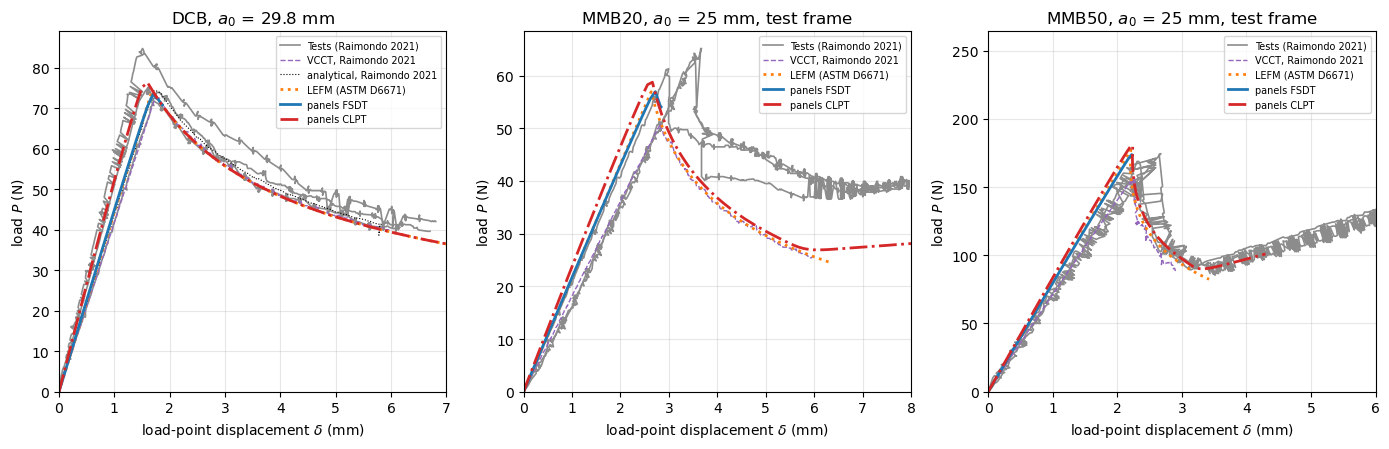

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6))
xlim = {'DCB': 7., 'MMB20': 8., 'MMB50': 6.}
for ax, key in zip(axes, tests):
    cs = {}
    for i, (d, P) in enumerate(curves[key]):
        cs['Tests (Raimondo 2021)' if i == 0 else '_test{0}'.format(i)] = (d, P, dict(color='0.55', lw=1.2))
    cs['VCCT, Raimondo 2021'] = (fe_curves[key][0], fe_curves[key][1], dict(color='C4', lw=1, ls='--'))
    if key == 'DCB':
        cs['analytical, Raimondo 2021'] = (analytical_dcb[0], analytical_dcb[1], dict(color='k', lw=0.8, ls=':'))
    cs['LEFM (ASTM D6671)'] = (lefm[key][0], lefm[key][1], dict(color='C1', ls=':', lw=2))
    for model, col in (('fsdt', 'C0'), ('clpt', 'C3')):
        name = '{0}_{1}'.format(key, model)
        if name in shifted:
            cs['panels ' + model.upper()] = shifted[name] + (dict(color=col, lw=2, ls='-' if model == 'fsdt' else '-.'),)
    mu.plot_test(ax, cs, title='{0}, $a_0$ = {1:g} mm{2}'.format(
        key, tests[key]['a0'], '' if key == 'DCB' else ', test frame'))
    ax.set_xlim(0, xlim[key])
    ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

In [11]:
info = ['| run | status | last crack length (mm) | increments | size | run time (min) | panels | machine | study run |',
        '|---|---|---|---|---|---|---|---|---|']
for name, res in runs.items():
    info.append('| {0} | {1} | {2:.1f} | {3} | {4} | {5:.1f} | {6} ({7}) | {8} | {9} |'.format(
        name, res['status'], res['a'][-1], len(res['delta']), res['size'], res['time']/60, res['panels_version'],
        res['panels_commit'][:7], res['machine'], res.get('source', '-')))
display(Markdown('\n'.join(info)))

| run | status | last crack length (mm) | increments | size | run time (min) | panels | machine | study run |
|---|---|---|---|---|---|---|---|---|
| DCB_fsdt | stopped at delta = 1.868457653473641 | 31.1 | 36 | 7800 | 22.1 | 0.16.0 (ec104c0) | AMD Ryzen 7 PRO 250 w/ Radeon 780M Graphics, 16 logical processors, Windows 11; shared with other runs | DCB_a29.8_fsdt_case4c_20261123_100041 |
| DCB_clpt | finished | 64.3 | 145 | 4512 | 30.6 | 0.16.0 (ec104c0) | AMD Ryzen 7 PRO 250 w/ Radeon 780M Graphics, 16 logical processors, Windows 11; shared with other runs | DCB_a29.8_clpt_case4c_20261123_091558 |
| MMB20_fsdt | stopped at delta = 3.3178276904296893 | 26.2 | 41 | 7400 | 23.2 | 0.16.0 (ec104c0) | AMD Ryzen 7 PRO 250 w/ Radeon 780M Graphics, 16 logical processors, Windows 11; shared with other runs | MMB20_a25_fsdt_case4c_20261123_074203 |
| MMB20_clpt | finished | 54.1 | 104 | 4440 | 23.3 | 0.16.0 (ec104c0) | AMD Ryzen 7 PRO 250 w/ Radeon 780M Graphics, 16 logical processors, Windows 11; shared with other runs | MMB20_a25_clpt_case4c_20261123_073215 |
| MMB50_fsdt | stopped at delta = 2.4607940269338378 | 25.0 | 35 | 7400 | 22.5 | 0.16.0 (ec104c0) | AMD Ryzen 7 PRO 250 w/ Radeon 780M Graphics, 16 logical processors, Windows 11; shared with other runs | MMB50_a25_fsdt_case4c_20261123_075538 |
| MMB50_clpt | stopped at delta = 4.516670550765734 | 52.0 | 266 | 4440 | 93.2 | 0.16.0 (ec104c0) | AMD Ryzen 7 PRO 250 w/ Radeon 780M Graphics, 16 logical processors, Windows 11; shared with other runs | MMB50_a25_clpt_case4c_loadline_20261123_081811 |

## Discussion

- **Peaks.** With the toughness of the VCCT analyses of Raimondo et al. and strengths from the literature, the peak loads of `panels` are within -10 to +5% of the mean of the tests: DCB -2.1% (CLPT) and -5.8% (FSDT), MMB 20% -7.5% and -10.3%, MMB 50% +5.3% and +1.3%. They are closer to the tests than the VCCT analyses (-7.0%, -19.8% and -8.8%).
- **Identified DCB crack length.** The DCB result rests on $a_0$ = 29.8 mm, identified from the analytical curve of Raimondo et al., not from the tests.
- **MMB 20% after the peak.** At $\delta$ = 5 mm `panels` (CLPT) is about 29% below the tests, like the VCCT analysis. In the study, the plateau toughness of Table 4 (0.322 N/mm at 20%) reduced this difference to 2.4%: the gap is the rise of the toughness with the crack growth, which the law with the onset toughness does not contain.
- **MMB 50%.** Under control of the load-line separation the CLPT model follows the tests through the load drop and into the rise of the load once the crack passes the saddle, up to $\delta$ = 4.5 mm, where the run reached the last crack length, 52 mm.
- **Initial stiffness.** The MMB models are 11-24% stiffer than the tests (study), although for the unidirectional arms of the AS4/PEEK case the FSDT model is within 1% of a solid model; the analyses of Raimondo et al. are also more compliant than beam theory. An uncorrected compliance of the apparatus is a possible cause; it was not checked.
- **Robustness.** Under control of the load-point displacement, the FSDT runs stall at or just after the peak: the DCB at $\delta$ = 1.87 mm, the MMB 20% at 3.32 mm and the MMB 50% at 2.46 mm, when the increments are cut below the minimum (the curves are shown up to there). Under load-line control the FSDT MMB runs went onto a branch with negative $\delta$ in the study and were stopped.